<center><b><font style="color: orange" size="5">Lab Session 3: Compressive Sensing and Image Denoising</font></b></center>
&ensp;

> Student 1:
>> First Name: Vu Minh Dang

>> Last Name: LE

# **Import dependencies:**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Load + grayscale image:**

In [ ]:
image_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/final-exam/baboon.png"

img_bgr = cv.imread(image_path)

print(f"Shape of original image is {img_bgr.shape}")

Shape of original image is (512, 512, 3)


In [ ]:
x_true = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

N, M = x_true.shape

In [ ]:
def make_random_mask(shape, sampling_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    mask = rng.random(shape) < sampling_ratio
    return mask

sampling_ratio = 0.2
mask = make_random_mask((N, M), sampling_ratio=sampling_ratio, seed=0)

y_obs = np.zeros_like(x_true)
y_obs[mask] = x_true[mask]

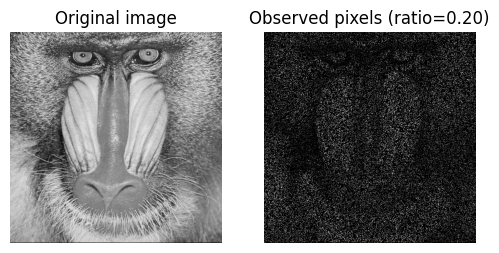

In [ ]:
plt.figure(figsize=(6,6))
plt.subplot(1,2,1)
plt.imshow(x_true, cmap="gray")
plt.title("Original image")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(y_obs, cmap="gray")
plt.title(f"Observed pixels (ratio={sampling_ratio:.2f})")
plt.axis("off")
plt.show()

In [ ]:
print(f"Shape of observation image is {y_obs.shape}")

Shape of observation image is (512, 512)


# **Fourier transform**

In [ ]:
def F(x):
    """2D FFT"""
    return np.fft.fft2(x)

def Finv(X):
    """2D inverse FFT"""
    return np.fft.ifft2(X)

# **Prox $f_1$: complex soft-threshold**

\begin{equation}
\operatorname{prox}_{\gamma \|\cdot\|_1}(\mathcal{Y})_{ij}
=
\begin{cases}
\left(1 - \dfrac{\gamma}{|\mathcal{Y}_{ij}|}\right)\mathcal{Y}_{ij},
& \text{if } |\mathcal{Y}_{ij}| > \gamma \\[6pt]
0, & \text{if } |\mathcal{Y}_{ij}| \le \gamma
\end{cases}
\end{equation}

In [ ]:
def soft_threshold_complex(Y, gamma):
    """
    Complex soft-thresholding function
    """
    mag = np.abs(Y)

    #scale = np.maximum(1.0 - gamma / (mag + 1e-12), 0.0) # avoid division by zero
    scale = np.maximum(1.0 - gamma / np.maximum(mag, 1e-12), 0.0)
    return scale * Y

# **Prox $f_2$: projection onto data constraint**

In [ ]:
def proj_data_consistency(V, mask, y_obs):
    x_temp = Finv(V)
    x_proj = x_temp.copy()
    x_proj[mask] = y_obs[mask]
    return F(x_proj)

# **Douglas-Rachford loop**

In [ ]:
def douglas_rachford_cs(y_obs, mask, gamma=0.02, rho=1.0, max_iter=300, tol=1e-5, verbose=True):
    """
    Douglas-Rachford for:
        min ||X||_1 + i_{data}(X)
    with variable X in Fourier domain.

    Returns:
      X_hat (Fourier solution), x_hat (spatial reconstruction real-valued), history dict
    """
    N, M = y_obs.shape

    # init: start from FFT of zero-filled observation
    U = F(y_obs)

    hist = {"rel_change": [], "constraint_res": [], "l1": []}

    for k in range(max_iter):
        X = soft_threshold_complex(U, gamma)              # prox f1
        V = 2 * X - U                                     # reflection
        Z = proj_data_consistency(V, mask, y_obs)         # prox f2 (projection)
        U_next = U + rho * (Z - X)                        # update

        # diagnostics
        rel_change = np.linalg.norm(U_next - U) / (np.linalg.norm(U) + 1e-12)
        # constraint residual in spatial domain on observed pixels
        x_tmp = Finv(X)
        constraint_res = np.linalg.norm((x_tmp - y_obs)[mask]) / (np.linalg.norm(y_obs[mask]) + 1e-12)
        l1_val = np.sum(np.abs(X))

        hist["rel_change"].append(rel_change)
        hist["constraint_res"].append(constraint_res)
        hist["l1"].append(l1_val)

        U = U_next

        if verbose and (k % 50 == 0 or k == max_iter - 1):
            print(f"iter {k:4d} | rel_change={rel_change:.2e} | constraint_res={constraint_res:.2e} | l1={l1_val:.2e}")

        if rel_change < tol:
            if verbose:
                print(f"Stop at iter {k} (rel_change < tol)")
            break

    X_hat = soft_threshold_complex(U, gamma)  # final estimate (prox f1 at last U)
    x_hat = np.real(Finv(X_hat))
    return X_hat, x_hat, hist

iter    0 | rel_change=2.96e-04 | constraint_res=1.22e-04 | l1=2.83e+07
iter   50 | rel_change=2.95e-04 | constraint_res=1.22e-04 | l1=2.82e+07
iter  100 | rel_change=2.95e-04 | constraint_res=1.22e-04 | l1=2.80e+07
iter  150 | rel_change=2.95e-04 | constraint_res=1.22e-04 | l1=2.78e+07
iter  200 | rel_change=2.94e-04 | constraint_res=1.22e-04 | l1=2.77e+07
iter  250 | rel_change=2.93e-04 | constraint_res=1.22e-04 | l1=2.75e+07
iter  300 | rel_change=2.93e-04 | constraint_res=1.22e-04 | l1=2.73e+07
iter  350 | rel_change=2.92e-04 | constraint_res=1.22e-04 | l1=2.72e+07
iter  400 | rel_change=2.92e-04 | constraint_res=1.22e-04 | l1=2.70e+07
iter  450 | rel_change=2.91e-04 | constraint_res=1.21e-04 | l1=2.69e+07
iter  500 | rel_change=2.90e-04 | constraint_res=1.21e-04 | l1=2.67e+07
iter  550 | rel_change=2.89e-04 | constraint_res=1.21e-04 | l1=2.66e+07
iter  600 | rel_change=2.89e-04 | constraint_res=1.21e-04 | l1=2.64e+07
iter  650 | rel_change=2.88e-04 | constraint_res=1.21e-04 | l1=2

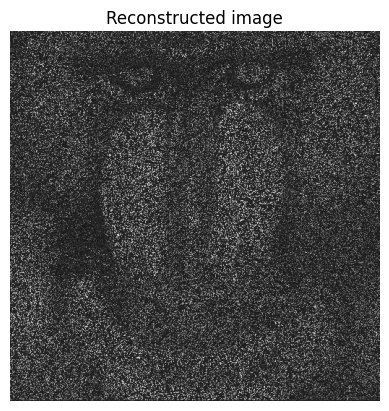

In [ ]:
gamma = 0.02   # bạn sẽ tune / sweep
rho = 2.0     # thường dùng 1.0
max_iter = 1000

X_hat, x_hat, hist = douglas_rachford_cs(
    y_obs=y_obs, mask=mask, gamma=gamma, rho=rho,
    max_iter=max_iter, tol=1e-6, verbose=True
)

plt.figure()
plt.imshow(x_hat, cmap="gray")
plt.title("Reconstructed image")
plt.axis("off")
plt.show()

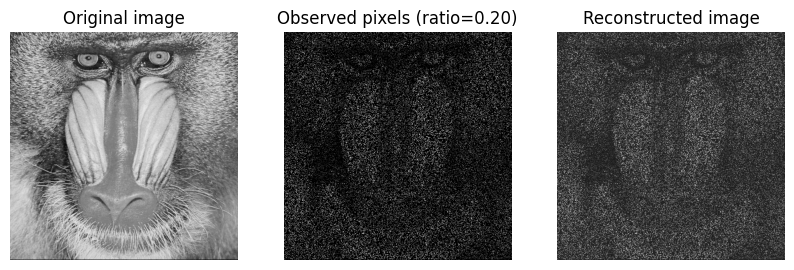

In [ ]:
plt.figure(figsize=(10,6))
plt.subplot(1,3,1)
plt.imshow(x_true, cmap="gray")
plt.title("Original image")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(y_obs, cmap="gray")
plt.title(f"Observed pixels (ratio={sampling_ratio:.2f})")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(x_hat, cmap="gray")
plt.title("Reconstructed image")
plt.axis("off")
plt.show()

# **Claude Code**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape of original image is (512, 512, 3)
Sampling ratio: 20.0%
Number of observed pixels: 52544 / 262144

Running Douglas-Rachford with gamma=1.5, rho=2...

Iter    0 | rel_change=2.22e-02 | constraint_res=9.17e-03 | l1=2.79e+07
Iter   50 | rel_change=1.11e-02 | constraint_res=3.51e-03 | l1=1.94e+07
Iter  100 | rel_change=5.95e-03 | constraint_res=5.69e-04 | l1=1.48e+07
Iter  150 | rel_change=4.45e-03 | constraint_res=3.41e-04 | l1=1.16e+07
Iter  200 | rel_change=3.42e-03 | constraint_res=2.52e-04 | l1=9.32e+06
Iter  250 | rel_change=2.65e-03 | constraint_res=2.17e-04 | l1=7.73e+06
Iter  300 | rel_change=2.06e-03 | constraint_res=1.79e-04 | l1=6.70e+06
Iter  350 | rel_change=1.61e-03 | constraint_res=1.51e-04 | l1=6.08e+06
Iter  400 | rel_change=1.30e-03 | constraint_res=1.17e-04 | l1=5.74e+06
Iter  450 | rel_change=1.11e-03 | constraint_res=8.78e-05 | l1=5.5

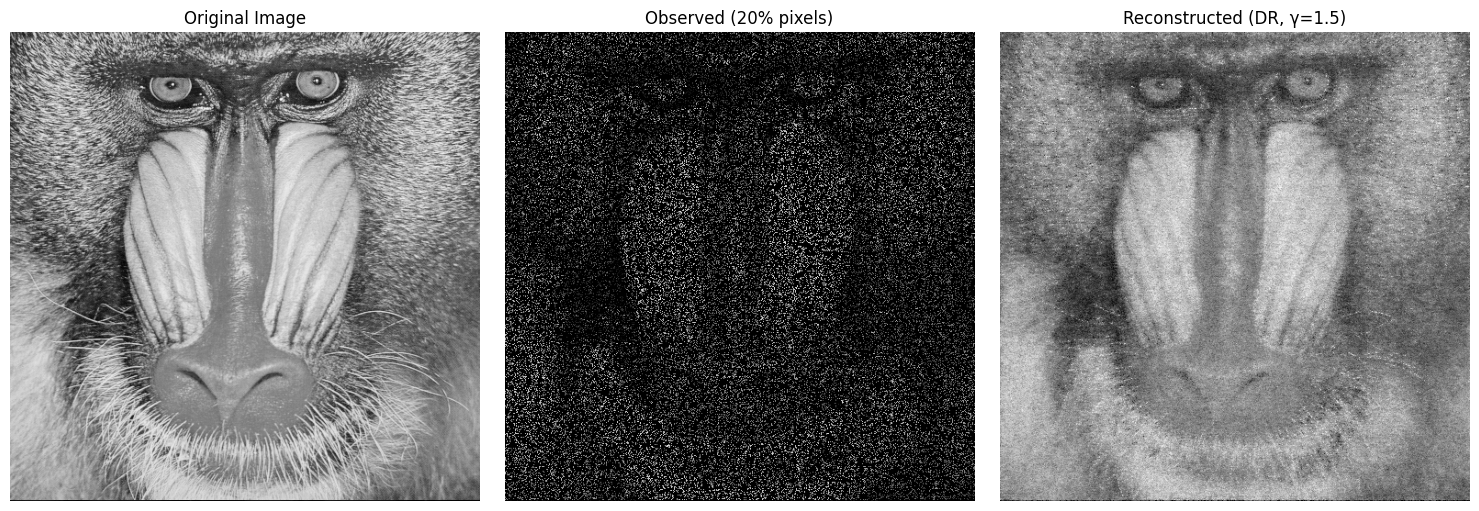

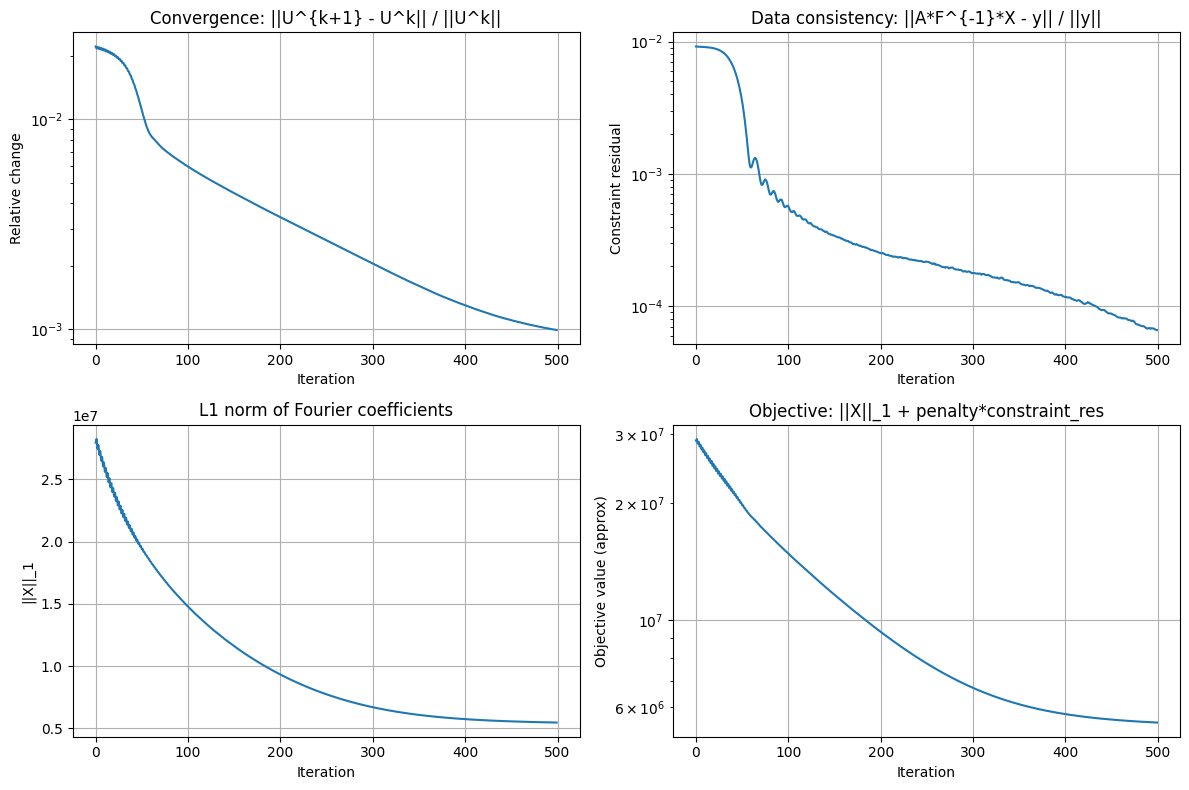


SUGGESTIONS:
1. Try different gamma values: [0.005, 0.01, 0.02, 0.05, 0.1]
2. Check if constraint_res converges to ~0
3. Visual quality vs sparsity trade-off
4. You can sweep gamma and plot NMSE curve


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from google.colab import drive

drive.mount('/content/drive')

image_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/final-exam/baboon.png"
img_bgr = cv.imread(image_path)
print(f"Shape of original image is {img_bgr.shape}")

x_true = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
N, M = x_true.shape

def make_random_mask(shape, sampling_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    mask = rng.random(shape) < sampling_ratio
    return mask

sampling_ratio = 0.2
mask = make_random_mask((N, M), sampling_ratio=sampling_ratio, seed=0)

# y chỉ chứa các giá trị tại vị trí mask=True
y_obs = np.zeros_like(x_true)
y_obs[mask] = x_true[mask]

def F(x):
    """2D FFT"""
    return np.fft.fft2(x)

def Finv(X):
    """2D inverse FFT"""
    return np.fft.ifft2(X)

def soft_threshold_complex(Y, gamma):
    """
    Complex soft-thresholding: prox of gamma*||.||_1
    For complex numbers: prox(y) = max(1 - gamma/|y|, 0) * y
    """
    mag = np.abs(Y)
    # Tránh chia cho 0
    scale = np.maximum(1.0 - gamma / np.maximum(mag, 1e-12), 0.0)
    return scale * Y

def proj_data_consistency(V, mask, y_obs):
    """
    Projection onto data consistency constraint.

    This implements prox_{i_C}(V) where C = {X : A*F^{-1}*X = y}
    Equivalently: pixels at mask positions must match y_obs.

    Method:
    - Transform V to spatial domain
    - Replace observed pixels with y_obs
    - Transform back to Fourier
    """
    x_temp = Finv(V)
    # Make a copy to avoid modifying in place
    x_proj = x_temp.copy()
    x_proj[mask] = y_obs[mask]
    return F(x_proj)

def douglas_rachford_cs(y_obs, mask, gamma=0.02, rho=1.0, max_iter=300, tol=1e-6, verbose=True):
    """
    Douglas-Rachford splitting for compressed sensing:
        min_X ||X||_1 + i_C(X)

    where X is in Fourier domain, C is data consistency constraint.

    Algorithm:
        X^k = prox_{gamma*||.||_1}(U^k)
        Z^k = prox_{i_C}(2*X^k - U^k)
        U^{k+1} = U^k + rho*(Z^k - X^k)

    Args:
        y_obs: observed image (sparse, zero elsewhere)
        mask: boolean mask of observed pixels
        gamma: prox step size (tune this!)
        rho: relaxation parameter (typically 1.0)
        max_iter: maximum iterations
        tol: tolerance for stopping criterion

    Returns:
        X_hat: solution in Fourier domain
        x_hat: reconstructed image (real part)
        hist: history dictionary
    """
    N, M = y_obs.shape

    # Initialize U: start from Fourier transform of observed data
    U = F(y_obs)

    hist = {
        "rel_change": [],
        "constraint_res": [],
        "l1": [],
        "obj": []
    }

    for k in range(max_iter):
        # Step 1: Proximal operator of f1 (soft-thresholding)
        X = soft_threshold_complex(U, gamma)

        # Step 2: Reflection
        V = 2.0 * X - U

        # Step 3: Proximal operator of f2 (projection onto data constraint)
        Z = proj_data_consistency(V, mask, y_obs)

        # Step 4: Update U
        U_next = U + rho * (Z - X)

        # === Diagnostics ===
        # Relative change in U
        rel_change = np.linalg.norm(U_next - U) / (np.linalg.norm(U) + 1e-12)

        # Data consistency residual (in spatial domain, on observed pixels)
        x_current = Finv(X)
        residual = (np.real(x_current) - y_obs)[mask]
        constraint_res = np.linalg.norm(residual) / (np.linalg.norm(y_obs[mask]) + 1e-12)

        # L1 norm of Fourier coefficients
        l1_val = np.sum(np.abs(X))

        # Objective value (approximate, since constraint is indicator function)
        obj_val = l1_val + 1e8 * constraint_res  # large penalty for constraint violation

        hist["rel_change"].append(rel_change)
        hist["constraint_res"].append(constraint_res)
        hist["l1"].append(l1_val)
        hist["obj"].append(obj_val)

        # Update
        U = U_next

        # Verbose output
        if verbose and (k % 50 == 0 or k == max_iter - 1):
            print(f"Iter {k:4d} | rel_change={rel_change:.2e} | "
                  f"constraint_res={constraint_res:.2e} | l1={l1_val:.2e}")

        # Stopping criterion
        if rel_change < tol:
            if verbose:
                print(f"Converged at iteration {k} (rel_change < {tol})")
            break

    # Final solution
    X_hat = soft_threshold_complex(U, gamma)
    x_hat = np.real(Finv(X_hat))

    # Clip to valid range
    x_hat = np.clip(x_hat, 0, 1)

    return X_hat, x_hat, hist

# Run reconstruction
gamma = 1.5   # Tune this! Try: 0.01, 0.02, 0.05, 0.1
rho = 2      # Usually keep at 1.0
max_iter = 500

print(f"Sampling ratio: {sampling_ratio*100:.1f}%")
print(f"Number of observed pixels: {np.sum(mask)} / {N*M}")
print(f"\nRunning Douglas-Rachford with gamma={gamma}, rho={rho}...\n")

X_hat, x_hat, hist = douglas_rachford_cs(
    y_obs=y_obs,
    mask=mask,
    gamma=gamma,
    rho=rho,
    max_iter=max_iter,
    tol=1e-6,
    verbose=True
)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original
axes[0].imshow(x_true, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Original Image')
axes[0].axis('off')

# Observed (sparse)
axes[1].imshow(y_obs, cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f'Observed ({sampling_ratio*100:.0f}% pixels)')
axes[1].axis('off')

# Reconstructed
axes[2].imshow(x_hat, cmap='gray', vmin=0, vmax=1)
axes[2].set_title(f'Reconstructed (DR, γ={gamma})')
axes[2].axis('off')

plt.tight_layout()
plt.show()

# Convergence plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].semilogy(hist['rel_change'])
axes[0, 0].set_xlabel('Iteration')
axes[0, 0].set_ylabel('Relative change')
axes[0, 0].set_title('Convergence: ||U^{k+1} - U^k|| / ||U^k||')
axes[0, 0].grid(True)

axes[0, 1].semilogy(hist['constraint_res'])
axes[0, 1].set_xlabel('Iteration')
axes[0, 1].set_ylabel('Constraint residual')
axes[0, 1].set_title('Data consistency: ||A*F^{-1}*X - y|| / ||y||')
axes[0, 1].grid(True)

axes[1, 0].plot(hist['l1'])
axes[1, 0].set_xlabel('Iteration')
axes[1, 0].set_ylabel('||X||_1')
axes[1, 0].set_title('L1 norm of Fourier coefficients')
axes[1, 0].grid(True)

axes[1, 1].semilogy(hist['obj'])
axes[1, 1].set_xlabel('Iteration')
axes[1, 1].set_ylabel('Objective value (approx)')
axes[1, 1].set_title('Objective: ||X||_1 + penalty*constraint_res')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Suggestion for parameter tuning
print("\n" + "="*60)
print("SUGGESTIONS:")
print("="*60)
print("1. Try different gamma values: [0.005, 0.01, 0.02, 0.05, 0.1]")
print("2. Check if constraint_res converges to ~0")
print("3. Visual quality vs sparsity trade-off")
print("4. You can sweep gamma and plot NMSE curve")

# **Greedy method**

In [ ]:
def nmse_fourier(X_hat, X_true):
    num = np.linalg.norm(X_hat - X_true)**2
    den = np.linalg.norm(X_true)**2 + 1e-12
    return num / den


def atom_restricted_to_mask(N, M, idx, mask_flat):
    """
    Build one Fourier atom restricted to observed pixels:
    atom = (ifft2(delta_idx)) evaluated at observed pixel locations
    Returns vector of length m (#observations), complex.
    """
    delta = np.zeros((N, M), dtype=np.complex128)
    delta[idx] = 1.0 + 0j
    spatial = np.fft.ifft2(delta)  # complex sinusoid pattern (scaled by numpy FFT conventions)
    return spatial.reshape(-1)[mask_flat]

def greedy_omp_fourier(
    x_true, y_obs, mask,
    K=200, tol=1e-6,
    verbose=True
):
    """
    OMP-style greedy recovery of sparse Fourier coefficients X (complex):
        y = A * ifft2(X)
    - Select one dominant frequency index per iteration (one-by-one).
    - Update coefficients by least squares on the selected support.

    Returns:
      X_hat (NxM complex), x_hat (NxM real), support list, history dict
    """
    N, M = y_obs.shape
    X_true = F(x_true)

    # Flatten helpers
    mask_flat = mask.reshape(-1)
    y_vec = y_obs.reshape(-1)[mask_flat].astype(np.complex128)  # measurements (real but cast to complex)

    # Current estimate in Fourier
    support = []
    support_set = set()
    coeffs = np.zeros((0,), dtype=np.complex128)  # coefficients on support

    # We'll store the LS design matrix columns incrementally
    G = np.zeros((y_vec.size, 0), dtype=np.complex128)

    hist = {"res_norm": [], "nmse_F": []}

    # Start from zero reconstruction
    X_hat = np.zeros((N, M), dtype=np.complex128)

    for k in range(K):
        # Current spatial estimate
        x_est = Finv(X_hat)
        x_est_vec = x_est.reshape(-1)[mask_flat]  # restricted to observed

        # Residual on observed pixels
        r_vec = y_vec - x_est_vec
        res_norm = np.linalg.norm(r_vec) / (np.linalg.norm(y_vec) + 1e-12)

        # Proxy correlation: FFT of zero-filled residual image
        r_img = np.zeros((N, M), dtype=np.complex128)
        r_img.reshape(-1)[mask_flat] = r_vec
        C = F(r_img)

        # Select dominant entry not yet in support
        # (avoid reselecting by zeroing already-selected indices)
        C_sel = C.copy()
        for idx in support_set:
            C_sel[idx] = 0.0
        new_idx = np.unravel_index(np.argmax(np.abs(C_sel)), C_sel.shape)

        support.append(new_idx)
        support_set.add(new_idx)

        # Add new column (atom restricted to mask) to G
        g_new = atom_restricted_to_mask(N, M, new_idx, mask_flat).reshape(-1, 1)
        G = np.hstack([G, g_new])

        # Least squares on support: min || y_vec - G a ||_2
        # Use lstsq for stability
        a_hat, *_ = np.linalg.lstsq(G, y_vec, rcond=None)
        coeffs = a_hat  # update coefficients

        # Update Fourier estimate X_hat on the support
        X_hat.fill(0.0)
        for idx, a in zip(support, coeffs):
            X_hat[idx] = a

        nmseF = nmse_fourier(X_hat, X_true)
        hist["res_norm"].append(res_norm)
        hist["nmse_F"].append(nmseF)

        if verbose and (k % 25 == 0 or k == K - 1):
            print(f"iter {k:4d} | support={len(support):4d} | res={res_norm:.2e} | NMSE_F={nmseF:.3e} | picked={new_idx}")

        if res_norm < tol:
            if verbose:
                print(f"Stop at iter {k}: residual < tol")
            break

    x_hat = np.real(Finv(X_hat))
    return X_hat, x_hat, support, hist

iter    0 | support=   1 | res=1.00e+00 | NMSE_F=9.760e-02 | picked=(np.int64(0), np.int64(0))
iter   25 | support=  26 | res=2.53e-01 | NMSE_F=6.414e-02 | picked=(np.int64(1), np.int64(510))
iter   50 | support=  51 | res=2.38e-01 | NMSE_F=5.703e-02 | picked=(np.int64(511), np.int64(10))
iter   75 | support=  76 | res=2.31e-01 | NMSE_F=5.379e-02 | picked=(np.int64(0), np.int64(10))
iter  100 | support= 101 | res=2.27e-01 | NMSE_F=5.201e-02 | picked=(np.int64(508), np.int64(0))
iter  125 | support= 126 | res=2.24e-01 | NMSE_F=5.069e-02 | picked=(np.int64(501), np.int64(1))
iter  150 | support= 151 | res=2.22e-01 | NMSE_F=4.959e-02 | picked=(np.int64(501), np.int64(0))
iter  175 | support= 176 | res=2.20e-01 | NMSE_F=4.869e-02 | picked=(np.int64(10), np.int64(511))
iter  200 | support= 201 | res=2.18e-01 | NMSE_F=4.797e-02 | picked=(np.int64(506), np.int64(507))
iter  225 | support= 226 | res=2.16e-01 | NMSE_F=4.731e-02 | picked=(np.int64(505), np.int64(4))
iter  250 | support= 251 | re

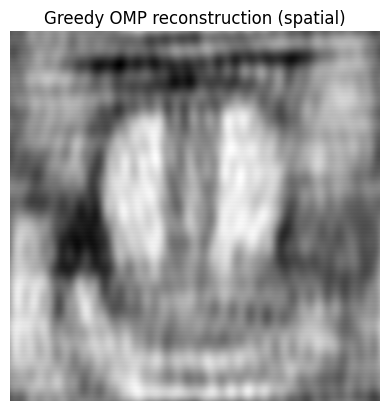

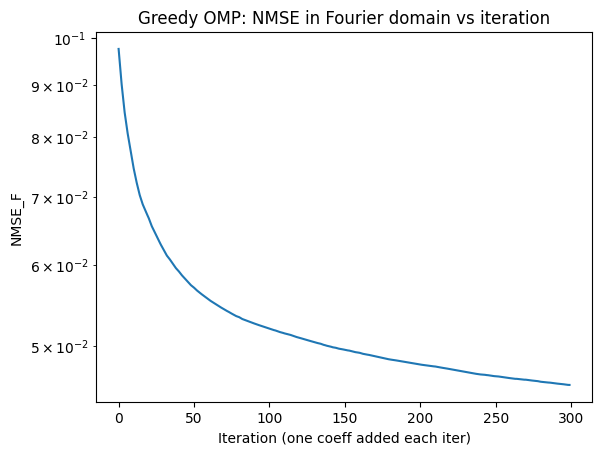

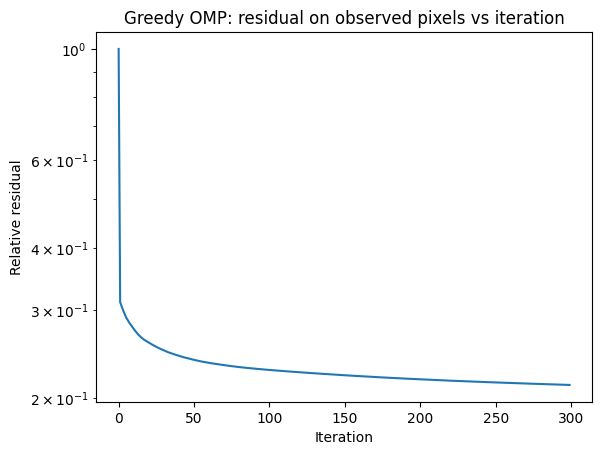

In [ ]:
K = 300  # number of dominant Fourier entries to retrieve one-by-one
X_hat_greedy, x_hat_greedy, support, hist_greedy = greedy_omp_fourier(
    x_true=x_true, y_obs=y_obs, mask=mask,
    K=K, tol=1e-6, verbose=True
)

X_true = F(x_true)
print("Final NMSE_F (greedy OMP) =", nmse_fourier(X_hat_greedy, X_true))

plt.figure()
plt.imshow(x_hat_greedy, cmap="gray")
plt.title("Greedy OMP reconstruction (spatial)")
plt.axis("off")
plt.show()

plt.figure()
plt.plot(hist_greedy["nmse_F"])
plt.yscale("log")
plt.title("Greedy OMP: NMSE in Fourier domain vs iteration")
plt.xlabel("Iteration (one coeff added each iter)")
plt.ylabel("NMSE_F")
plt.show()

plt.figure()
plt.plot(hist_greedy["res_norm"])
plt.yscale("log")
plt.title("Greedy OMP: residual on observed pixels vs iteration")
plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.show()